# TP4 — RNN, LSTM, Transformer, mini-GPT et mini-BERT

**Livrable.** Ce notebook répond à la première partie et aux trois exercices de `architecture_transformer.ipynb`.
Les exemples GPT et BERT de la première partie sont réalisés et testés dans les exercices 2 et 3,
avec des modèles Transformer entraînés localement, sans téléchargement de poids pré-entraînés.
Exécuter les cellules dans l'ordre depuis le dossier `TP4`. Les résultats dépendent de la graine et du CPU.


In [1]:
from __future__ import annotations

import copy
import math
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd()
print("PyTorch:", torch.__version__, "| appareil:", DEVICE)


PyTorch: 2.12.0+cpu | appareil: cpu


## Partie 1 — Prévision de la sinusoïde

Chaque entrée contient 10 valeurs consécutives de $\sin(x)$ ; la cible est la valeur immédiatement suivante.
Le découpage est chronologique pour simuler une prévision sur les observations futures.


In [2]:
x_axis = torch.linspace(0, 20, 200)
series = torch.sin(x_axis)
WINDOW = 10
features = torch.stack([series[i:i + WINDOW] for i in range(len(series) - WINDOW)]).unsqueeze(-1)
targets = series[WINDOW:].unsqueeze(-1)
X_train, X_test = features[:150].to(DEVICE), features[150:].to(DEVICE)
y_train, y_test = targets[:150].to(DEVICE), targets[150:].to(DEVICE)
assert X_train.shape == (150, 10, 1) and y_test.shape == (40, 1)
print("Train:", tuple(X_train.shape), "| Test:", tuple(X_test.shape))


Train: (150, 10, 1) | Test: (40, 10, 1)


In [3]:
class SineRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.RNN(1, 16, batch_first=True)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        states, _ = self.recurrent(x)
        return self.head(states[:, -1])


class SineLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.LSTM(1, 16, batch_first=True)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        states, _ = self.recurrent(x)
        return self.head(states[:, -1])


class SineTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(1, 16)
        self.position = nn.Embedding(WINDOW, 16)
        layer = nn.TransformerEncoderLayer(16, 2, 32, dropout=0.0, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device)
        states = self.encoder(self.projection(x) + self.position(positions))
        return self.head(states[:, -1])


def train_sine(model, epochs=250):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()
    history = []
    for epoch in range(epochs):
        model.train()
        loss = criterion(model(X_train), y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    model.eval()
    with torch.no_grad():
        pred = model(X_test).cpu().numpy().ravel()
    return model, history, pred


sine_results = {}
for name, model in [("RNN", SineRNN()), ("LSTM", SineLSTM()), ("Transformer", SineTransformer())]:
    fitted, history, pred = train_sine(model)
    mse = float(np.mean((pred - y_test.cpu().numpy().ravel()) ** 2))
    sine_results[name] = {"model": fitted, "history": history, "pred": pred, "mse": mse}
    print(f"{name:12s} | MSE test: {mse:.6f} | premier réel/prédit: {y_test[0].item():.3f}/{pred[0]:.3f}")


RNN          | MSE test: 0.000050 | premier réel/prédit: -0.364/-0.361


LSTM         | MSE test: 0.000012 | premier réel/prédit: -0.364/-0.362


Transformer  | MSE test: 0.000083 | premier réel/prédit: -0.364/-0.372


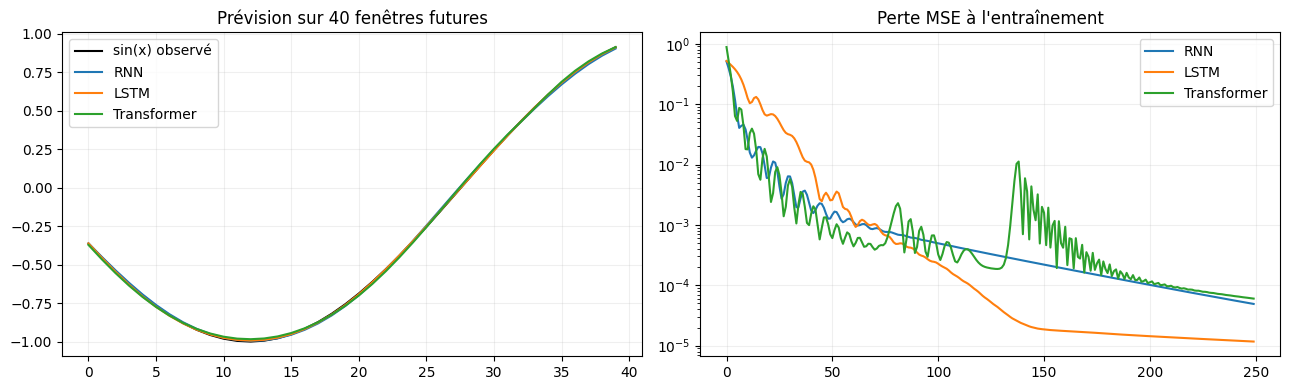

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(y_test.cpu().numpy().ravel(), label="sin(x) observé", color="black")
for name, result in sine_results.items():
    axes[0].plot(result["pred"], label=name)
    axes[1].plot(result["history"], label=name)
axes[0].set_title("Prévision sur 40 fenêtres futures")
axes[1].set_title("Perte MSE à l'entraînement")
axes[1].set_yscale("log")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## Exercice 1 — Consommation électrique horaire

Le fichier ZIP fourni contient `household_power_consumption.txt`. On calcule la moyenne de
`Global_active_power` par heure et on conserve les heures comportant au moins 45 mesures valides.
Le découpage 70/15/15 et la normalisation utilisent exclusivement la partie entraînement.
Les fenêtres de validation et de test peuvent regarder les 24 heures précédentes : ces heures sont
des observations déjà disponibles au moment de prédire. Les métriques sont calculées en kW.


In [5]:
zip_path = ROOT / "individual+household+electric+power+consumption.zip"
if not zip_path.exists():
    raise FileNotFoundError(f"Placer le ZIP fourni par le professeur ici : {zip_path}")
with zipfile.ZipFile(zip_path) as archive:
    with archive.open("household_power_consumption.txt") as stream:
        df = pd.read_csv(
            stream, sep=";", usecols=["Date", "Time", "Global_active_power"],
            na_values=["?"], low_memory=False,
        )
dates = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
power = pd.Series(pd.to_numeric(df["Global_active_power"], errors="coerce").to_numpy(), index=dates)
hourly = power.resample("h").agg(["mean", "count"])
series_hourly = hourly["mean"].where(hourly["count"] >= 45)
total_hours = len(series_hourly)
end_train, end_val = int(0.70 * total_hours), int(0.85 * total_hours)
mean_train = float(series_hourly.iloc[:end_train].mean())
std_train = float(series_hourly.iloc[:end_train].std())
assert std_train > 0
scaled = ((series_hourly - mean_train) / std_train).to_numpy(dtype=np.float32)
print("Heures totales:", total_hours, "| heures valides:", int(series_hourly.notna().sum()))
print(f"Normalisation train: moyenne={mean_train:.4f} kW, écart-type={std_train:.4f} kW")


Heures totales: 34589 | heures valides: 34151
Normalisation train: moyenne=1.0865 kW, écart-type=0.9287 kW


In [6]:
def make_hourly_windows(values, length=24):
    inputs, labels, indices = [], [], []
    for index in range(length, len(values)):
        sequence, target = values[index - length:index], values[index]
        if np.isfinite(sequence).all() and np.isfinite(target):
            inputs.append(sequence)
            labels.append(target)
            indices.append(index)
    return (
        torch.tensor(np.asarray(inputs), dtype=torch.float32).unsqueeze(-1),
        torch.tensor(np.asarray(labels), dtype=torch.float32).unsqueeze(-1),
        np.asarray(indices),
    )


energy_X, energy_y, target_index = make_hourly_windows(scaled)
train_select = target_index < end_train
val_select = (target_index >= end_train) & (target_index < end_val)
test_select = target_index >= end_val
train_loader = DataLoader(TensorDataset(energy_X[train_select], energy_y[train_select]), batch_size=256, shuffle=True)
val_loader = DataLoader(TensorDataset(energy_X[val_select], energy_y[val_select]), batch_size=512)
test_loader = DataLoader(TensorDataset(energy_X[test_select], energy_y[test_select]), batch_size=512)
assert all(len(loader.dataset) for loader in (train_loader, val_loader, test_loader))
print("Fenêtres train/validation/test:", *(len(loader.dataset) for loader in (train_loader, val_loader, test_loader)))


Fenêtres train/validation/test: 23805 5054 4932


In [7]:
class EnergyTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(1, 32)
        self.positions = nn.Embedding(24, 32)
        layer = nn.TransformerEncoderLayer(
            d_model=32, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.head = nn.Linear(32, 1)

    def forward(self, x):
        assert x.ndim == 3 and x.shape[1:] == (24, 1)
        positions = torch.arange(24, device=x.device)
        hidden = self.encoder(self.projection(x) + self.positions(positions))
        return self.head(hidden[:, -1, :])


energy_model = EnergyTransformer().to(DEVICE)
assert energy_model(torch.zeros(2, 24, 1, device=DEVICE)).shape == (2, 1)
print("EnergyTransformer : (batch, 24, 1) → (batch, 1)")


EnergyTransformer : (batch, 24, 1) → (batch, 1)


In [8]:
def mean_mse(model, loader):
    model.eval()
    squared, count = 0.0, 0
    with torch.no_grad():
        for batch_x, batch_y in loader:
            prediction = model(batch_x.to(DEVICE))
            squared += nn.functional.mse_loss(prediction, batch_y.to(DEVICE), reduction="sum").item()
            count += batch_y.numel()
    return squared / count


optimizer = torch.optim.Adam(energy_model.parameters(), lr=0.001)
best_loss = float("inf")
best_state = None
stale_epochs = 0
energy_history = []
for epoch in range(1, 21):
    energy_model.train()
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
        loss = nn.functional.mse_loss(energy_model(batch_x), batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    val_loss = mean_mse(energy_model, val_loader)
    energy_history.append(val_loss)
    print(f"Époque {epoch:02d} | MSE validation = {val_loss:.5f}")
    if val_loss < best_loss - 1e-5:
        best_loss, best_state, stale_epochs = val_loss, copy.deepcopy(energy_model.state_dict()), 0
    else:
        stale_epochs += 1
    if stale_epochs >= 3:
        print("Arrêt anticipé après 3 époques sans amélioration.")
        break
energy_model.load_state_dict(best_state)


Époque 01 | MSE validation = 0.42087


Époque 02 | MSE validation = 0.40742


Époque 03 | MSE validation = 0.41902


Époque 04 | MSE validation = 0.40040


Époque 05 | MSE validation = 0.39629


Époque 06 | MSE validation = 0.39137


... (6 outputs left out)

Époque 13 | MSE validation = 0.38501


Époque 14 | MSE validation = 0.38123


Époque 15 | MSE validation = 0.38670
Arrêt anticipé après 3 époques sans amélioration.


<All keys matched successfully>

Transformer  | MAE = 0.3437 kW | RMSE = 0.4946 kW
Persistance  | MAE = 0.3892 kW | RMSE = 0.5884 kW
J-1 (24 h)   | MAE = 0.5133 kW | RMSE = 0.7639 kW


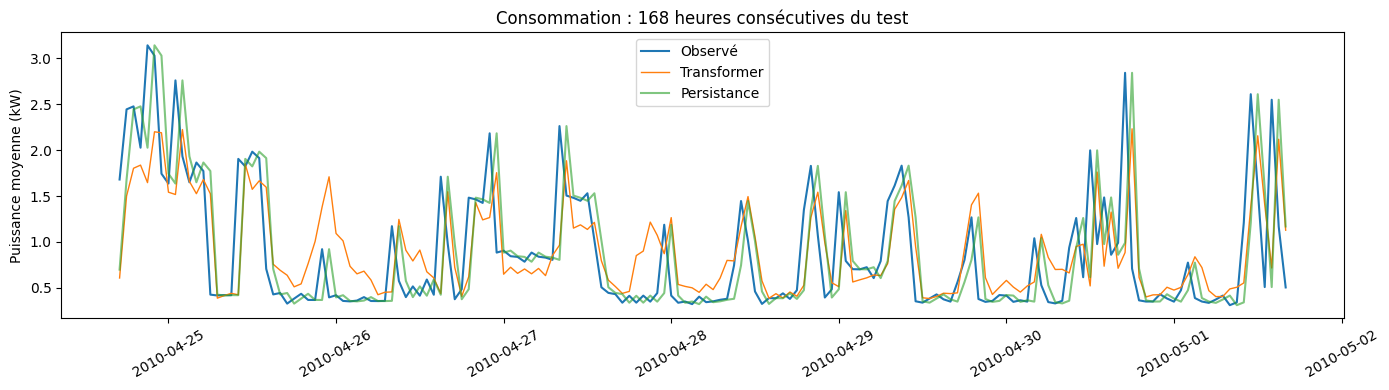

In [9]:
energy_model.eval()
with torch.no_grad():
    prediction_scaled = torch.cat([energy_model(batch_x.to(DEVICE)).cpu() for batch_x, _ in test_loader]).numpy().ravel()
truth_scaled = energy_y[test_select].numpy().ravel()
inputs_scaled = energy_X[test_select].numpy().squeeze(-1)
truth_kw = truth_scaled * std_train + mean_train
model_kw = prediction_scaled * std_train + mean_train
persistence_kw = inputs_scaled[:, -1] * std_train + mean_train
daily_kw = inputs_scaled[:, 0] * std_train + mean_train

def metrics(real, predicted):
    return float(np.mean(np.abs(real - predicted))), float(np.sqrt(np.mean((real - predicted) ** 2)))

energy_scores = {name: metrics(truth_kw, pred) for name, pred in [
    ("Transformer", model_kw), ("Persistance", persistence_kw), ("J-1 (24 h)", daily_kw)
]}
for name, (mae, rmse) in energy_scores.items():
    print(f"{name:12s} | MAE = {mae:.4f} kW | RMSE = {rmse:.4f} kW")

test_indices = target_index[test_select]
week_start = next(
    (i for i in range(len(test_indices) - 167) if np.all(np.diff(test_indices[i:i + 168]) == 1)),
    None,
)
if week_start is None:
    raise RuntimeError("Aucune fenêtre de 168 heures consécutives dans le test")
week = slice(week_start, week_start + 168)
week_dates = series_hourly.index[test_indices[week]]
plt.figure(figsize=(14, 4))
plt.plot(week_dates, truth_kw[week], label="Observé", linewidth=1.5)
plt.plot(week_dates, model_kw[week], label="Transformer", linewidth=1)
plt.plot(week_dates, persistence_kw[week], label="Persistance", alpha=0.6)
plt.title("Consommation : 168 heures consécutives du test")
plt.ylabel("Puissance moyenne (kW)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Réflexion.** La comparaison avec les deux références est chiffrée ci-dessus : regarder les deux
métriques avant de conclure. Une fenêtre de 168 h pourrait capter les habitudes hebdomadaires,
mais il faut réentraîner et comparer sur le même test. L'heure et le jour donnent des repères
calendaires qui ne sont pas explicites dans la puissance seule. Calculer moyenne et écart-type
sur le test introduirait une fuite d'information. Pour prédire l'énergie horaire en kWh, il faut
intégrer la puissance sur chaque heure (somme des mesures en kW × 1/60 h si elles sont espacées
d'une minute) et utiliser cette énergie comme cible ; une moyenne en kW n'est pas une énergie.
